# Superstore Dataset — Data Analysis & Visualization

**Project:** Superstore Sales Analysis  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, KaggleHub

This notebook downloads the Superstore dataset from Kaggle, cleans the data, performs exploratory data analysis, creates visualizations, and produces business insights.


In [1]:
# 1. Install and import libraries
!pip -q install kagglehub openpyxl

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, glob

sns.set_theme(style="whitegrid")

# Download latest dataset
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Dataset path:", path)
print("Files:", os.listdir(path))


Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Dataset path: /kaggle/input/superstore-dataset-final
Files: ['Sample - Superstore.csv']


In [2]:
import pandas as pd
import glob
import os

# 2. Load the dataset automatically
files = glob.glob(os.path.join(path, "*"))
print(files)

data_file = next(
    (f for f in files if f.lower().endswith((".csv", ".xlsx", ".xls"))),
    None
)

print("Using file:", data_file)

if data_file.lower().endswith(".csv"):
    df = pd.read_csv(data_file, encoding="latin1")
else:
    df = pd.read_excel(data_file)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

['/kaggle/input/superstore-dataset-final/Sample - Superstore.csv']
Using file: /kaggle/input/superstore-dataset-final/Sample - Superstore.csv
Rows: 9994
Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# 3. Basic data understanding
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:


,Data Type
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object



Missing values:


,Missing Values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# 4. Data cleaning
df = df.drop_duplicates()

# Convert dates
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Create useful date features
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.month_name()
df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (9994, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month_Name,Year_Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,2015-10


## 5. Key Performance Indicators

We calculate total sales, profit, quantity, orders, customers, and overall profit margin.


In [5]:
# 5. KPI analysis
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
profit_margin = total_profit / total_sales * 100

kpis = pd.DataFrame({
    "Metric": [
        "Total Sales", "Total Profit", "Total Quantity",
        "Unique Orders", "Unique Customers", "Profit Margin"
    ],
    "Value": [
        total_sales, total_profit, total_quantity,
        total_orders, total_customers, profit_margin
    ]
})

display(kpis)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")


,Metric,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Quantity,3.787300e+04
3,Unique Orders,5.009000e+03
4,Unique Customers,7.930000e+02
5,Profit Margin,1.246722e+01


Total Sales: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%


## 6. Sales and Profit by Category

In [6]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

display(category_analysis)


,Sales,Profit,Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906


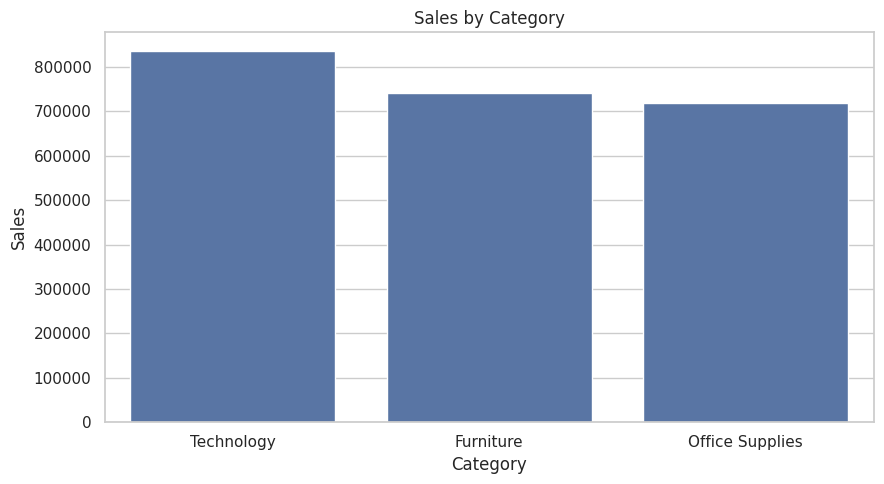

In [7]:
# Sales by category
plt.figure(figsize=(9, 5))
sns.barplot(data=category_analysis.reset_index(), x="Category", y="Sales")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


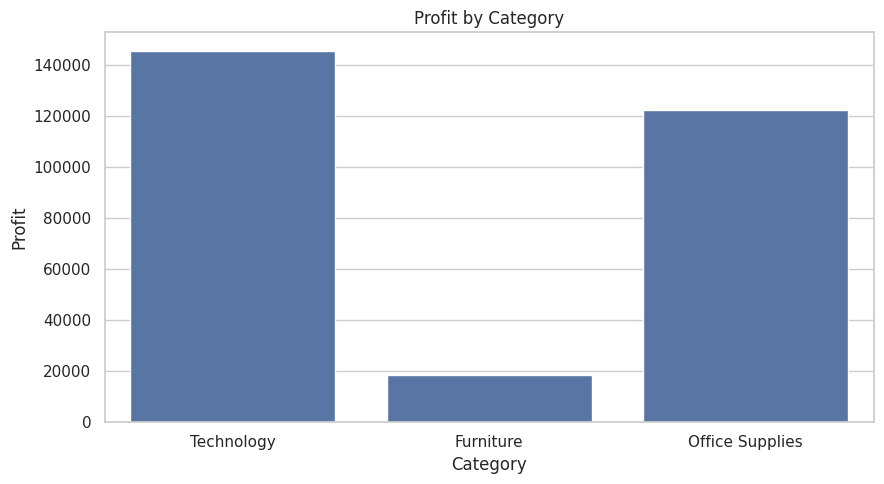

In [8]:
# Profit by category
plt.figure(figsize=(9, 5))
sns.barplot(data=category_analysis.reset_index(), x="Category", y="Profit")
plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


## 7. Sub-Category Analysis

In [9]:
subcategory_analysis = (
    df.groupby("Sub-Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Profit", ascending=False)
)

display(subcategory_analysis)


,Sales,Profit,Quantity
Sub-Category,,,
Copiers,149528.0300,55617.8249,234
Phones,330007.0540,44515.7306,3289
Accessories,167380.3180,41936.6357,2976
Paper,78479.2060,34053.5693,5178
Binders,203412.7330,30221.7633,5974
Chairs,328449.1030,26590.1663,2356
Storage,223843.6080,21278.8264,3158
Appliances,107532.1610,18138.0054,1729
Furnishings,91705.1640,13059.1436,3563


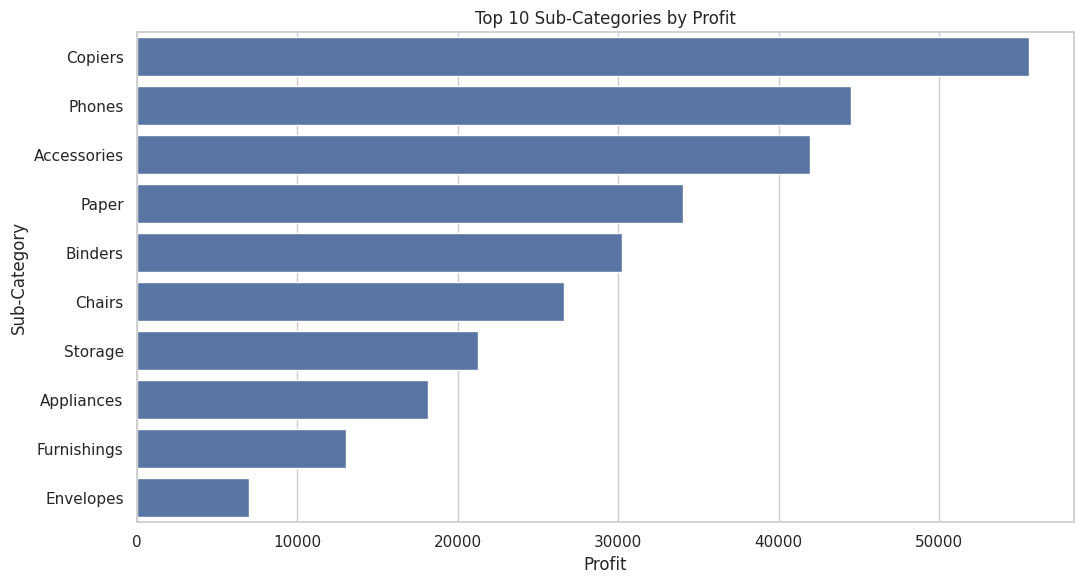

In [10]:
# Top 10 sub-categories by profit
top_subcategories = subcategory_analysis.head(10).reset_index()

plt.figure(figsize=(11, 6))
sns.barplot(data=top_subcategories, y="Sub-Category", x="Profit")
plt.title("Top 10 Sub-Categories by Profit")
plt.xlabel("Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


## 8. Regional Analysis

In [11]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

display(region_analysis)


,Sales,Profit,Orders
Region,,,
West,725457.8245,108418.4489,1611
East,678781.2400,91522.7800,1401
Central,501239.8908,39706.3625,1175
South,391721.9050,46749.4303,822


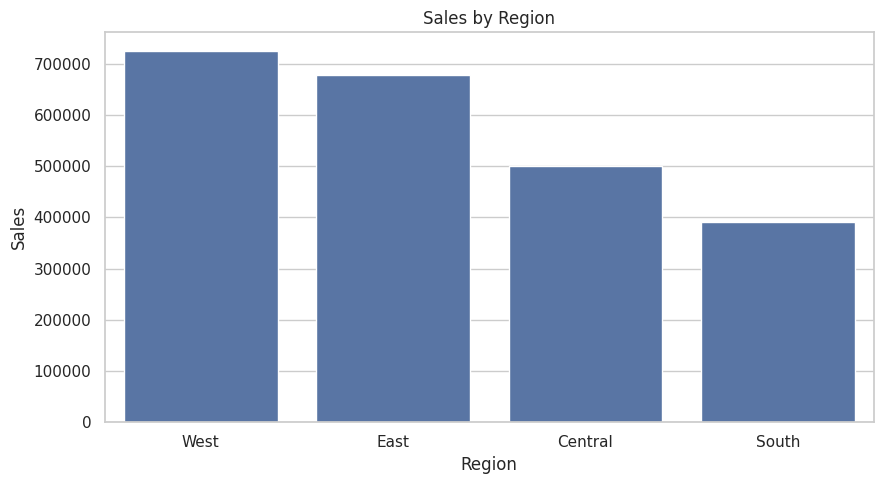

In [12]:
plt.figure(figsize=(9, 5))
sns.barplot(data=region_analysis.reset_index(), x="Region", y="Sales")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


## 9. Monthly Sales and Profit Trends

In [13]:
monthly = (
    df.groupby("Year_Month")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

display(monthly.head())


,Year_Month,Sales,Profit
0,2014-01,14236.895,2450.1907
1,2014-02,4519.892,862.3084
2,2014-03,55691.009,498.7299
3,2014-04,28295.345,3488.8352
4,2014-05,23648.287,2738.7096


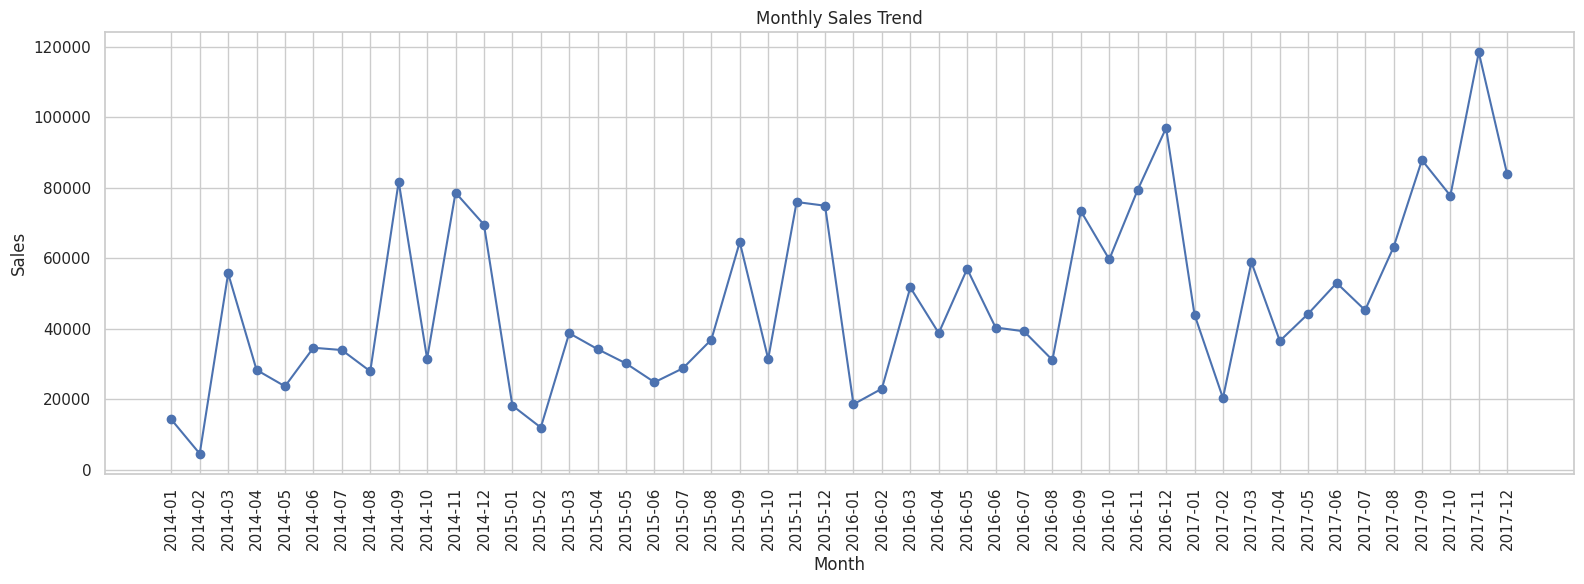

In [14]:
plt.figure(figsize=(16, 6))
plt.plot(monthly["Year_Month"], monthly["Sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


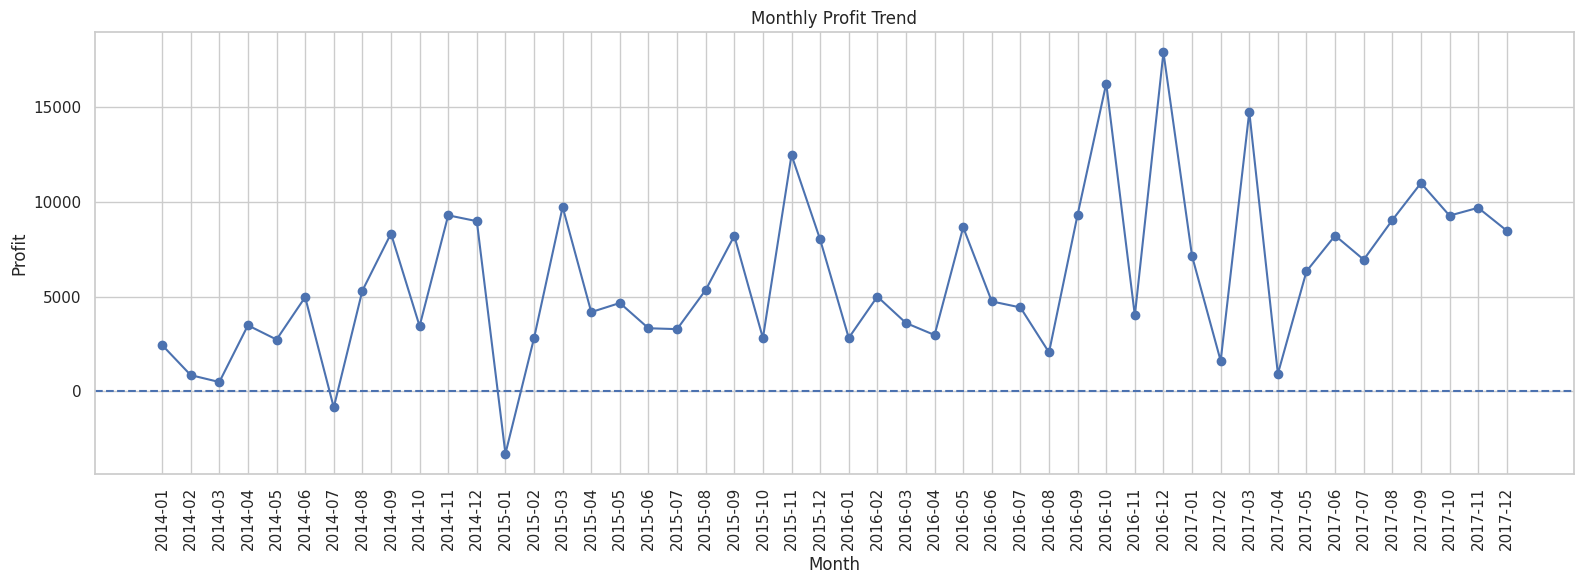

In [15]:
plt.figure(figsize=(16, 6))
plt.plot(monthly["Year_Month"], monthly["Profit"], marker="o")
plt.axhline(0, linestyle="--")
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 10. Yearly Performance

In [ ]:
yearly = (
    df.groupby("Year")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

display(yearly)


,Year,Sales,Profit
0,2014,484247.4981,49543.9741
1,2015,470532.5090,61618.6037
2,2016,609205.5980,81795.1743
3,2017,733215.2552,93439.2696


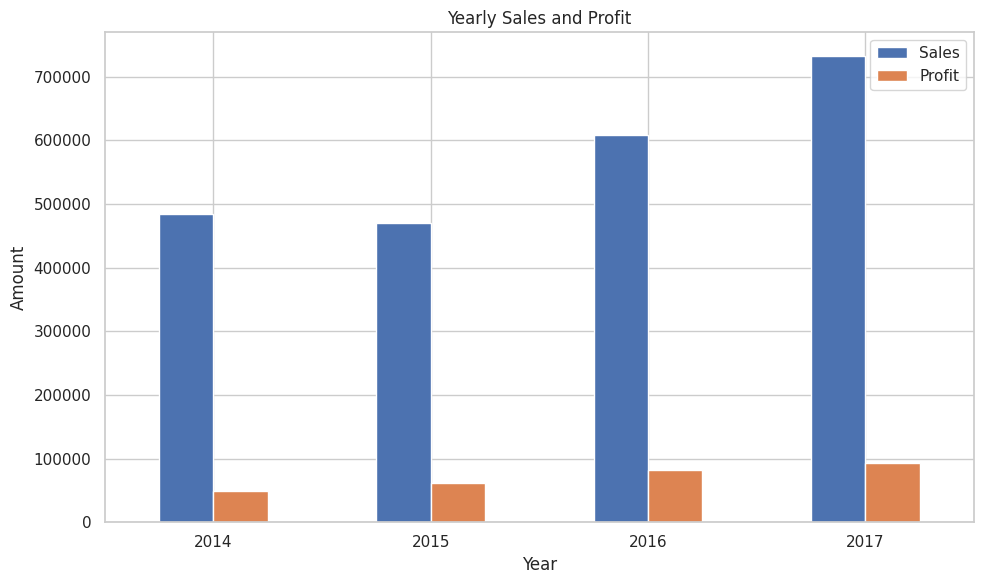

In [ ]:
yearly.set_index("Year")[["Sales", "Profit"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Yearly Sales and Profit")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Top and Lowest-Performing Products

In [ ]:
product_analysis = (
    df.groupby("Product Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

top_products = product_analysis.sort_values("Sales", ascending=False).head(10)
loss_products = product_analysis.sort_values("Profit").head(10)

print("Top 10 Products by Sales")
display(top_products)

print("10 Lowest-Profit Products")
display(loss_products)


Top 10 Products by Sales


,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27


10 Lowest-Profit Products


,Sales,Profit,Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22
Balt Solid Wood Round Tables,6518.754,-1201.0581,19


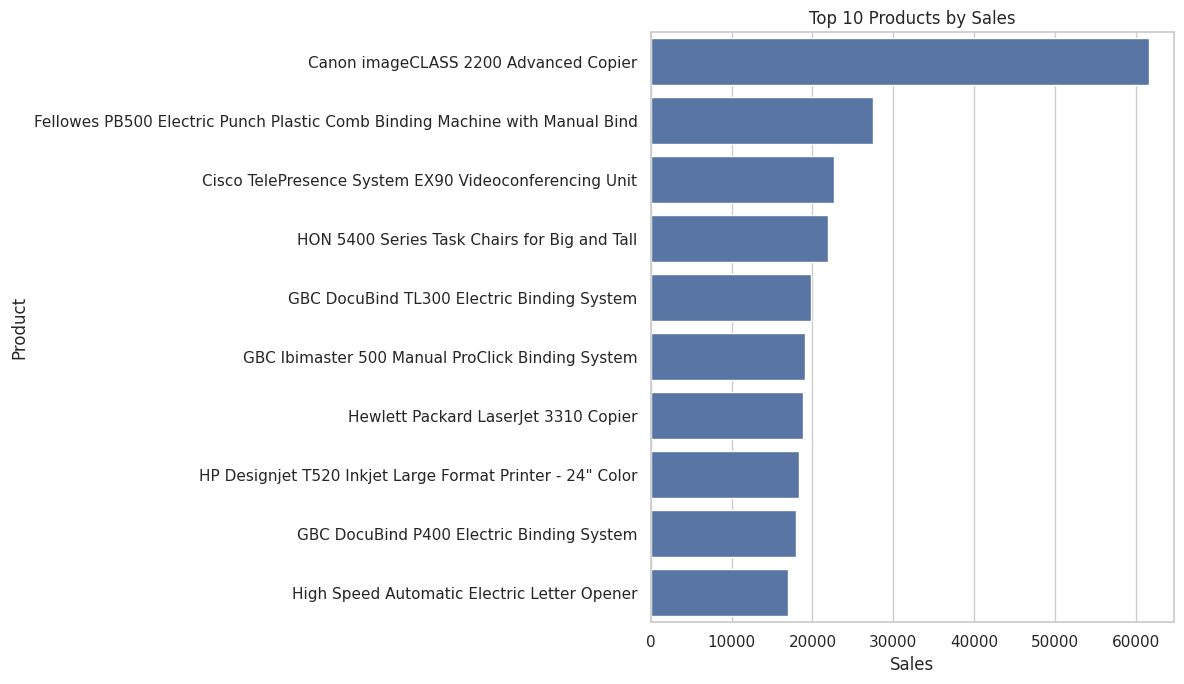

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_products.reset_index(),
    y="Product Name",
    x="Sales"
)
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


## 12. Discount vs Profit

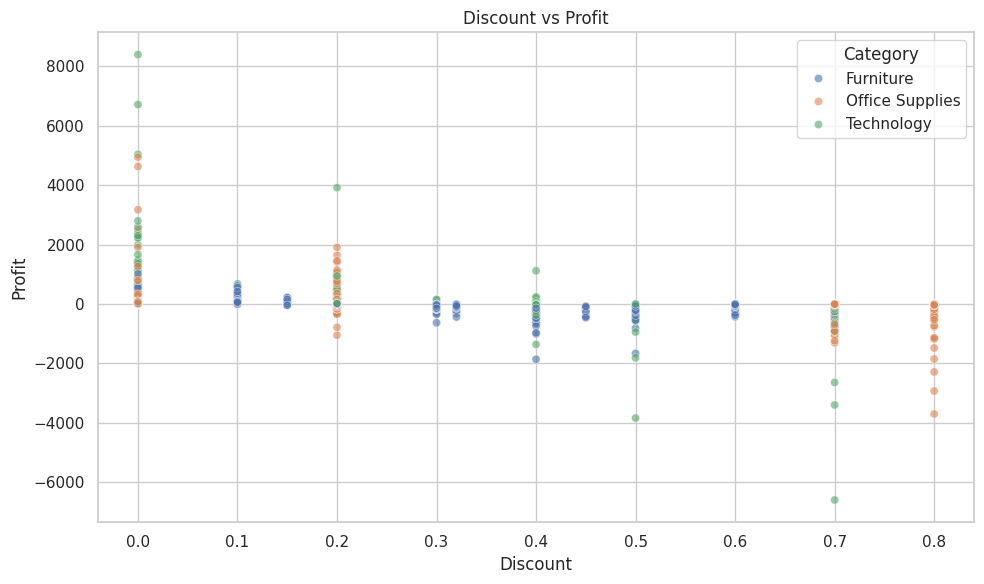

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


## 13. Customer and Shipping Analysis

In [ ]:
customer_analysis = (
    df.groupby("Customer Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

print("Top 10 Customers")
display(customer_analysis.head(10))

shipping_analysis = (
    df.groupby("Ship Mode")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

print("Shipping Mode Analysis")
display(shipping_analysis)


Top 10 Customers


,Sales,Profit,Orders
Customer Name,,,
Sean Miller,25043.050,-1980.7393,5
Tamara Chand,19052.218,8981.3239,5
Raymond Buch,15117.339,6976.0959,6
Tom Ashbrook,14595.620,4703.7883,4
Adrian Barton,14473.571,5444.8055,10
Ken Lonsdale,14175.229,806.8550,12
Sanjit Chand,14142.334,5757.4119,9
Hunter Lopez,12873.298,5622.4292,6
Sanjit Engle,12209.438,2650.6769,11


Shipping Mode Analysis


,Sales,Profit,Orders
Ship Mode,,,
Standard Class,1.358216e+06,164088.7875,2994
Second Class,4.591936e+05,57446.6354,964
First Class,3.514284e+05,48969.8399,787
Same Day,1.283631e+05,15891.7589,264


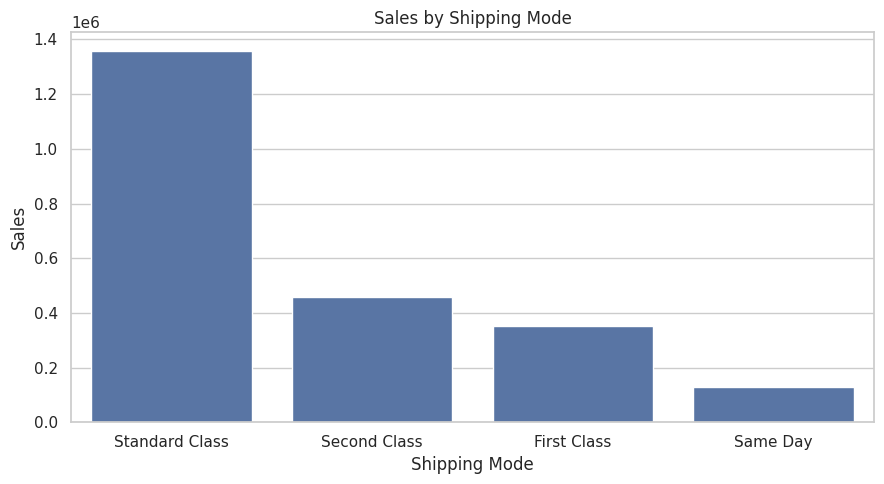

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(data=shipping_analysis.reset_index(), x="Ship Mode", y="Sales")
plt.title("Sales by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


## 14. Automatic Business Insights

In [ ]:
best_category = category_analysis["Sales"].idxmax()
most_profitable_category = category_analysis["Profit"].idxmax()
best_region = region_analysis["Sales"].idxmax()
most_profitable_subcategory = subcategory_analysis["Profit"].idxmax()
best_product = top_products.index[0]
worst_product = loss_products.index[0]

print("========== BUSINESS INSIGHTS ==========")
print(f"1. Highest-sales category: {best_category}")
print(f"2. Most profitable category: {most_profitable_category}")
print(f"3. Highest-sales region: {best_region}")
print(f"4. Most profitable sub-category: {most_profitable_subcategory}")
print(f"5. Highest-sales product: {best_product}")
print(f"6. Lowest-profit product in the bottom group: {worst_product}")
print(f"7. Overall profit margin: {profit_margin:.2f}%")


========== BUSINESS INSIGHTS ==========
1. Highest-sales category: Technology
2. Most profitable category: Technology
3. Highest-sales region: West
4. Most profitable sub-category: Copiers
5. Highest-sales product: Canon imageCLASS 2200 Advanced Copier
6. Lowest-profit product in the bottom group: Cubify CubeX 3D Printer Double Head Print
7. Overall profit margin: 12.47%


## 15. Final Conclusion

The analysis identifies the strongest categories, regions, products, customers, and sales periods. It also examines profitability and the relationship between discounts and profit.

**Recommended business focus:**
- Increase investment in high-profit categories and sub-categories.
- Investigate products with consistently negative or very low profit.
- Monitor high-discount transactions because excessive discounts can reduce profitability.
- Use regional and monthly trends to improve sales planning.


In [ ]:
# 16. Export results to Excel
with pd.ExcelWriter("Superstore_Analysis.xlsx") as writer:
    df.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    kpis.to_excel(writer, sheet_name="KPIs", index=False)
    category_analysis.to_excel(writer, sheet_name="Category")
    subcategory_analysis.to_excel(writer, sheet_name="Subcategory")
    region_analysis.to_excel(writer, sheet_name="Region")
    monthly.to_excel(writer, sheet_name="Monthly", index=False)
    yearly.to_excel(writer, sheet_name="Yearly", index=False)
    top_products.to_excel(writer, sheet_name="Top_Products")
    loss_products.to_excel(writer, sheet_name="Loss_Products")
    customer_analysis.head(20).to_excel(writer, sheet_name="Top_Customers")
    shipping_analysis.to_excel(writer, sheet_name="Shipping")

print("Done! Superstore_Analysis.xlsx has been created.")


Done! Superstore_Analysis.xlsx has been created.
